# Food Delivery Demand Prediction
## Exploratory Data Analysis (EDA)
**Course:** Predictive Analysis  
**Department:** Computer Science & Engineering, Manipal University Jaipur  
**Objective:** Perform a rigorous exploratory data analysis on historical food delivery order records across 77 fulfillment centers and 51 meal items over 145 weeks.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

import warnings
warnings.filterwarnings('ignore')


### 1. Dataset Acquisition and Merging
We load the three core datasets:
1. `train.csv`: Historical order records with weekly grain.
2. `fulfilment_center_info.csv`: Center metadata (city, region, type, operational area).
3. `meal_info.csv`: Meal metadata (category and cuisine).


In [2]:
train = pd.read_csv('archive/train.csv')
centers = pd.read_csv('archive/fulfilment_center_info.csv')
meals = pd.read_csv('archive/meal_info.csv')

print(f"Train shape: {train.shape}")
print(f"Centers shape: {centers.shape}")
print(f"Meals shape: {meals.shape}")

# Merge into unified analysis dataframe
df = train.merge(centers, on='center_id', how='left').merge(meals, on='meal_id', how='left')
print(f"Merged dataset shape: {df.shape}")
df.head()


Train shape: (456548, 9)
Centers shape: (77, 5)
Meals shape: (51, 3)
Merged dataset shape: (456548, 15)


,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,city_code,region_code,center_type,op_area,category,cuisine
0,1379560,1,55,1885,136.83,152.29,0,0,177,647,56,TYPE_C,2.0,Beverages,Thai
1,1466964,1,55,1993,136.83,135.83,0,0,270,647,56,TYPE_C,2.0,Beverages,Thai
2,1346989,1,55,2539,134.86,135.86,0,0,189,647,56,TYPE_C,2.0,Beverages,Thai
3,1338232,1,55,2139,339.50,437.53,0,0,54,647,56,TYPE_C,2.0,Beverages,Indian
4,1448490,1,55,2631,243.50,242.50,0,0,40,647,56,TYPE_C,2.0,Beverages,Indian


### 2. Data Cleaning & Integrity Check
Check for missing values, duplicates, and attribute types.


In [3]:
print("Missing values per feature:")
print(df.isnull().sum())
print(f"\nTotal duplicate rows: {df.duplicated().sum()}")
df.info()


Missing values per feature:
id                       0
week                     0
center_id                0
meal_id                  0
checkout_price           0
base_price               0
emailer_for_promotion    0
homepage_featured        0
num_orders               0
city_code                0
region_code              0
center_type              0
op_area                  0
category                 0
cuisine                  0
dtype: int64



Total duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 456548 entries, 0 to 456547
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   id                     456548 non-null  int64  
 1   week                   456548 non-null  int64  
 2   center_id              456548 non-null  int64  
 3   meal_id                456548 non-null  int64  
 4   checkout_price         456548 non-null  float64
 5   base_price             456548 non-null  float64
 6   emailer_for_promotion  456548 non-null  int64  
 7   homepage_featured      456548 non-null  int64  
 8   num_orders             456548 non-null  int64  
 9   city_code              456548 non-null  int64  
 10  region_code            456548 non-null  int64  
 11  center_type            456548 non-null  object 
 12  op_area                456548 non-null  float64
 13  category               456548 non-null  object 
 14  cuisine    

### 3. Feature Engineering for EDA
Deriving operational indicators:
- `discount`: Absolute discount in currency (`base_price - checkout_price`)
- `discount_pct`: Percentage discount
- `log_orders`: $\log(1 + \text{num\_orders})$ for variance stabilization


In [4]:
df['discount'] = df['base_price'] - df['checkout_price']
df['discount_pct'] = (df['discount'] / df['base_price']) * 100
df['log_orders'] = np.log1p(df['num_orders'])

df[['checkout_price', 'base_price', 'discount', 'discount_pct', 'num_orders', 'op_area']].describe().T


,count,mean,std,min,25%,50%,75%,max
checkout_price,456548.0,332.238933,152.939723,2.970000,228.950000,296.820000,445.230000,866.27000
base_price,456548.0,354.156627,160.715914,55.350000,243.500000,310.460000,458.870000,866.27000
discount,456548.0,21.917695,48.495857,-185.300000,-1.000000,1.000000,16.520000,561.60000
discount_pct,456548.0,5.719500,11.362753,-72.789753,-0.145406,0.141217,6.242147,99.06087
num_orders,456548.0,261.872760,395.922798,13.000000,54.000000,136.000000,324.000000,24299.00000
op_area,456548.0,4.083590,1.091686,0.900000,3.600000,4.000000,4.500000,7.00000


### 4. Target Variable Analysis (`num_orders`)
Examining skewness and kurtosis of raw demand vs. log-transformed demand.


Raw Demand Skewness: 6.93, Kurtosis: 121.85
Log Demand Skewness: -0.02, Kurtosis: -0.60


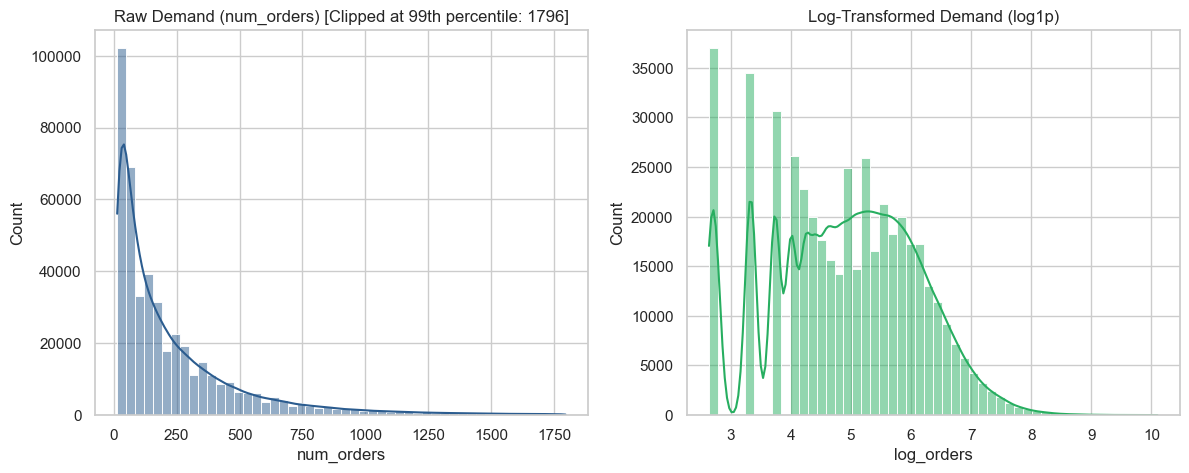

In [5]:
raw_skew = df['num_orders'].skew()
raw_kurt = df['num_orders'].kurtosis()
log_skew = df['log_orders'].skew()
log_kurt = df['log_orders'].kurtosis()

print(f"Raw Demand Skewness: {raw_skew:.2f}, Kurtosis: {raw_kurt:.2f}")
print(f"Log Demand Skewness: {log_skew:.2f}, Kurtosis: {log_kurt:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
q99 = df['num_orders'].quantile(0.99)
sns.histplot(df[df['num_orders'] <= q99]['num_orders'], bins=50, kde=True, ax=axes[0], color='#2b5c8f')
axes[0].set_title(f'Raw Demand (num_orders) [Clipped at 99th percentile: {q99:.0f}]')

sns.histplot(df['log_orders'], bins=50, kde=True, ax=axes[1], color='#27ae60')
axes[1].set_title('Log-Transformed Demand (log1p)')
plt.show()


### 5. Aggregate Weekly Demand Trends & Seasonality
Tracking cumulative orders over the 145-week timeline.


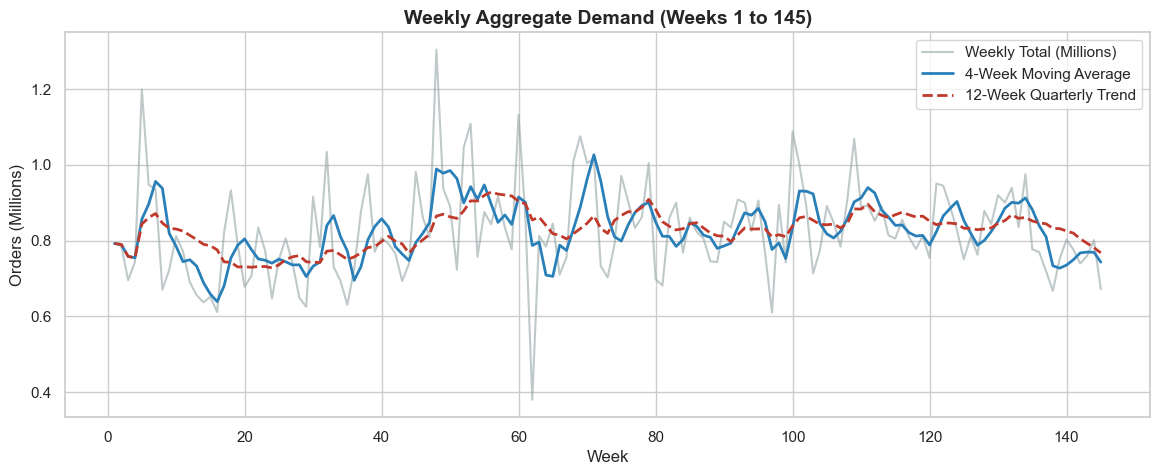

In [6]:
weekly = df.groupby('week')['num_orders'].sum().reset_index()
weekly['rolling_4w'] = weekly['num_orders'].rolling(4, min_periods=1).mean()
weekly['rolling_12w'] = weekly['num_orders'].rolling(12, min_periods=1).mean()

plt.figure(figsize=(14, 5))
plt.plot(weekly['week'], weekly['num_orders'] / 1e6, label='Weekly Total (Millions)', color='#95a5a6', alpha=0.6)
plt.plot(weekly['week'], weekly['rolling_4w'] / 1e6, label='4-Week Moving Average', color='#2980b9', linewidth=2)
plt.plot(weekly['week'], weekly['rolling_12w'] / 1e6, label='12-Week Quarterly Trend', color='#c0392b', linewidth=2, linestyle='--')
plt.title('Weekly Aggregate Demand (Weeks 1 to 145)', fontsize=14, fontweight='bold')
plt.xlabel('Week')
plt.ylabel('Orders (Millions)')
plt.legend()
plt.show()


### 6. Promotional Campaign Impact
Examining the lift provided by emailers and homepage featuring.


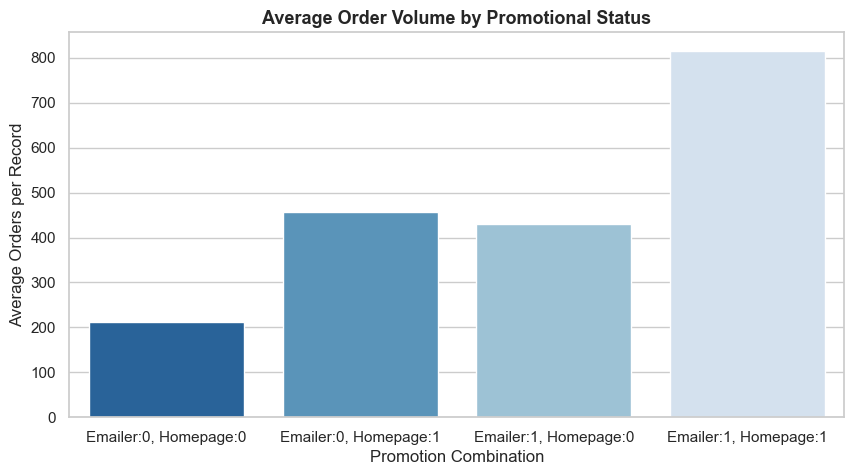

In [7]:
promo_df = df.groupby(['emailer_for_promotion', 'homepage_featured'])['num_orders'].agg(['mean', 'median', 'count']).reset_index()
promo_df['promo_type'] = promo_df.apply(lambda r: f"Emailer:{int(r['emailer_for_promotion'])}, Homepage:{int(r['homepage_featured'])}", axis=1)

plt.figure(figsize=(10, 5))
sns.barplot(data=promo_df, x='promo_type', y='mean', palette='Blues_r')
plt.title('Average Order Volume by Promotional Status', fontsize=13, fontweight='bold')
plt.xlabel('Promotion Combination')
plt.ylabel('Average Orders per Record')
plt.show()


### 7. Cuisine & Category Breakdown
Evaluating demand distribution across product offerings.


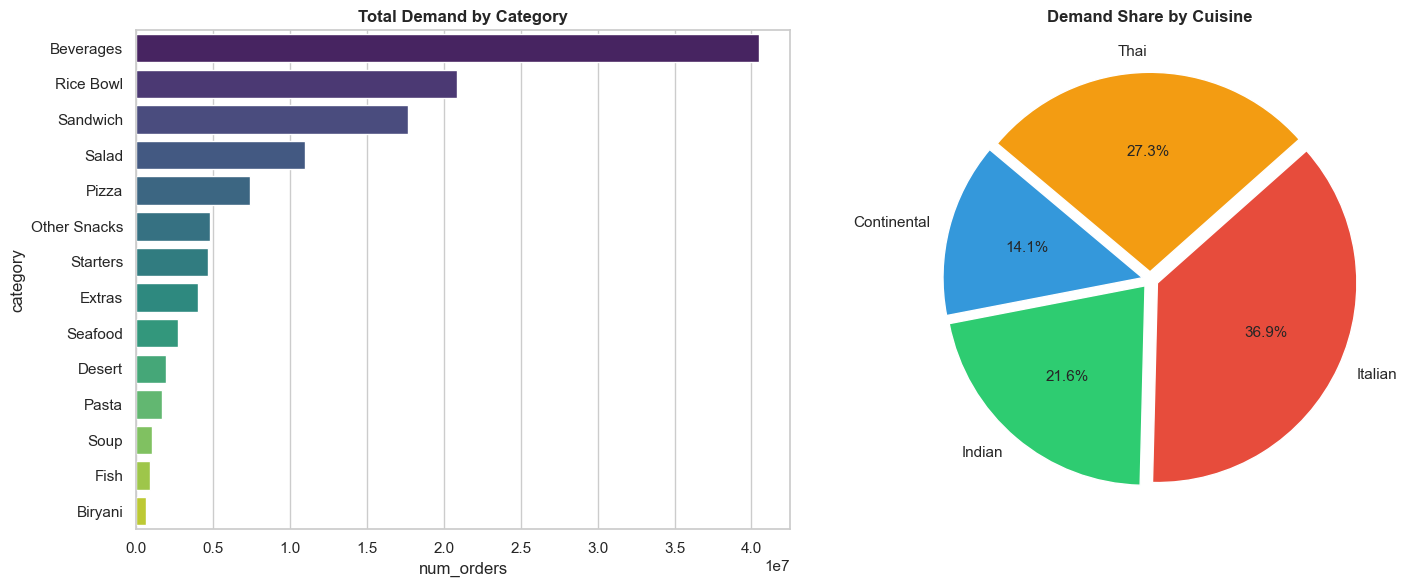

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

cat_totals = df.groupby('category')['num_orders'].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=cat_totals, x='num_orders', y='category', palette='viridis', ax=axes[0])
axes[0].set_title('Total Demand by Category', fontweight='bold')

cuisine_totals = df.groupby('cuisine')['num_orders'].sum().reset_index()
axes[1].pie(cuisine_totals['num_orders'], labels=cuisine_totals['cuisine'], autopct='%1.1f%%',
            startangle=140, colors=['#3498db', '#2ecc71', '#e74c3c', '#f39c12'], explode=[0.04]*4)
axes[1].set_title('Demand Share by Cuisine', fontweight='bold')
plt.tight_layout()
plt.show()


### 8. Fulfillment Center Operational Characteristics
Investigating center types and operational areas.


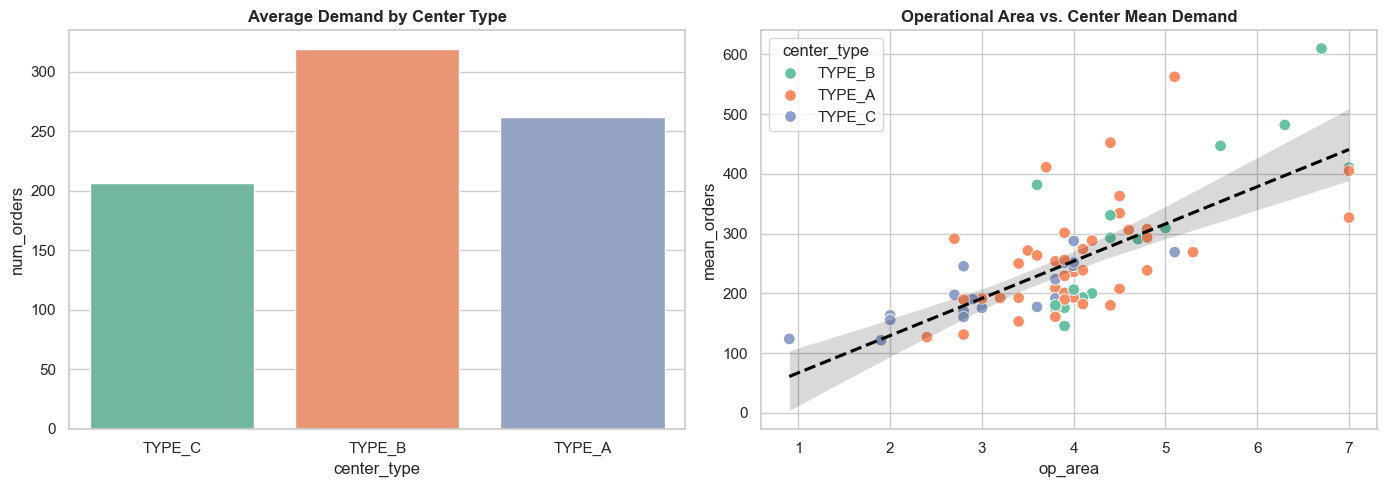

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df, x='center_type', y='num_orders', palette='Set2', errorbar=None, ax=axes[0])
axes[0].set_title('Average Demand by Center Type', fontweight='bold')

center_summary = df.groupby('center_id').agg(op_area=('op_area', 'first'), mean_orders=('num_orders', 'mean'), center_type=('center_type', 'first')).reset_index()
sns.scatterplot(data=center_summary, x='op_area', y='mean_orders', hue='center_type', palette='Set2', s=70, ax=axes[1])
sns.regplot(data=center_summary, x='op_area', y='mean_orders', scatter=False, ax=axes[1], color='black', line_kws={'linestyle':'--'})
axes[1].set_title('Operational Area vs. Center Mean Demand', fontweight='bold')
plt.tight_layout()
plt.show()


### 9. Correlation Analysis
Pearson correlation between all numerical predictors and demand.


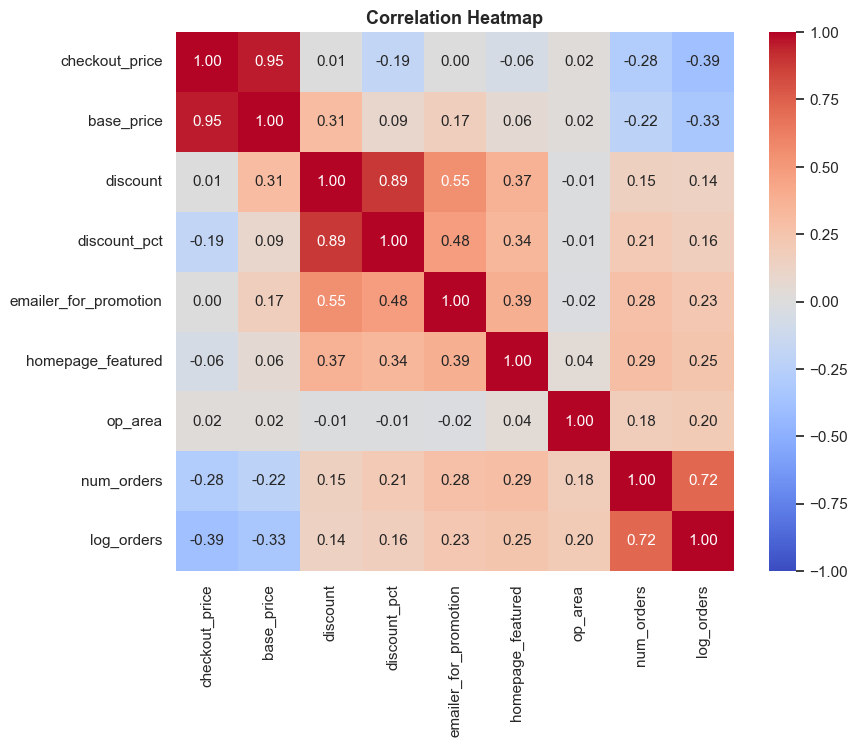

In [10]:
numeric_cols = ['checkout_price', 'base_price', 'discount', 'discount_pct',
                'emailer_for_promotion', 'homepage_featured', 'op_area', 'num_orders', 'log_orders']

plt.figure(figsize=(9, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap', fontsize=13, fontweight='bold')
plt.show()


### 10. Time-Aware Feature Engineering (Leakage-Free)
To prepare the dataset for predictive models (Poisson Regression, Negative Binomial, and Time Series Forecasting) without data leakage:
1. **Cyclic Calendar Terms**: Sine and Cosine harmonic transformations of weekly cycle ($\sin(2\pi \cdot \text{week}/52)$).
2. **Exact Center-Meal Lags**: Shift historical orders by exact week increments ($t-1, t-2, t-4$) grouped on `[center_id, meal_id]`.
3. **Trailing Rolling Statistics**: 4-week and 8-week trailing rolling averages.
4. **Time-Aware Validation Split**: Partition chronologically (e.g. Weeks 1–120 for training, Weeks 121–145 for testing).


In [11]:
fe = df.copy()

# Cyclical week signals
fe['week_scaled'] = (fe['week'] - fe['week'].min()) / (fe['week'].max() - fe['week'].min())
fe['week_sin'] = np.sin(2 * np.pi * fe['week'] / 52)
fe['week_cos'] = np.cos(2 * np.pi * fe['week'] / 52)
fe['checkout_to_base_ratio'] = np.where(fe['base_price'] != 0, fe['checkout_price'] / fe['base_price'], np.nan)

# Exact historical lags per center-meal pair
for lag in [1, 2, 4]:
    lookup = train[['center_id', 'meal_id', 'week', 'num_orders']].copy()
    lookup['week'] += lag
    lookup = lookup.rename(columns={'num_orders': f'orders_lag_{lag}w'})
    fe = fe.merge(lookup, on=['center_id', 'meal_id', 'week'], how='left')

# Trailing rolling means
for window in [4, 8]:
    cols = []
    for l in range(1, window + 1):
        c = f'orders_lag_{l}w'
        if c not in fe.columns:
            lookup = train[['center_id', 'meal_id', 'week', 'num_orders']].copy()
            lookup['week'] += l
            lookup = lookup.rename(columns={'num_orders': c})
            fe = fe.merge(lookup, on=['center_id', 'meal_id', 'week'], how='left')
        cols.append(c)
    fe[f'rolling_mean_{window}w'] = fe[cols].mean(axis=1, skipna=True)

# Train/Test Split (Temporal)
train_mask = fe['week'] <= 120
test_mask = fe['week'] > 120

print('Engineered Features:', [c for c in fe.columns if 'lag' in c or 'rolling' in c or 'week_' in c])
print(f"Train set: {train_mask.sum()} records (Weeks {fe.loc[train_mask, 'week'].min()} to {fe.loc[train_mask, 'week'].max()})")
print(f"Test set: {test_mask.sum()} records (Weeks {fe.loc[test_mask, 'week'].min()} to {fe.loc[test_mask, 'week'].max()})")


Engineered Features: ['week_scaled', 'week_sin', 'week_cos', 'orders_lag_1w', 'orders_lag_2w', 'orders_lag_4w', 'orders_lag_3w', 'rolling_mean_4w', 'orders_lag_5w', 'orders_lag_6w', 'orders_lag_7w', 'orders_lag_8w', 'rolling_mean_8w']
Train set: 374398 records (Weeks 1 to 120)
Test set: 82150 records (Weeks 121 to 145)


### 11. Summary & Modeling Roadmap
- **Dataset Hygiene**: 456,548 clean observations across 145 weeks with zero missing values in primary tables.
- **Target Distribution**: Severe positive skewness ($+6.93$) cured by logarithmic transformation ($\log(1+x)$ skewness $-0.02$).
- **Predictors Ready**: Engineered price elasticity, promotional interaction terms, center capacity metrics, cyclical time features, and historical lag windows.
- **Next Phase**: Train baseline model, Count Models (**Poisson** and **Negative Binomial**), and evaluate against **MAE** and **RMSE**.
